# Chapter 8: Hierarchical Clustering

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from scipy.stats import mode
import scipy.cluster.hierarchy as shc
from sklearn.datasets import load_digits
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import pairwise_distances_argmin

# On Windows, scikit-learn can warn about a memory leak in KMeans. This is harmless for our small datasets.
warnings.filterwarnings('ignore', message='KMeans is known to have a memory leak')

## 8.1 Introduction & Motivation

The k-Means algorithm works very well when we know beforehand how many clusters we expect to find. When we don't, we have to fit several k-Means models with different values of k and compare them, as we did with the elbow method. **Hierarchical clustering** takes a different approach: it builds the clusters for *every* possible number of clusters in a single run.

| | k-Means | Hierarchical clustering |
|---|---|---|
| **Number of clusters** | Chosen *before* fitting | Chosen *after* fitting, by cutting the tree |
| **Result** | One grouping into k clusters | A full hierarchy (tree) of clusters |
| **Randomness** | Depends on the random starting centers | Deterministic: same result on every run |
| **Speed** | Fast, also on large datasets | Slow on large datasets |
| **New observations** | `predict()` assigns them to the nearest center | No `predict()` in scikit-learn |

**Key advantage:** we don't need to specify the number of clusters upfront. We get a hierarchy that we can cut at any level to obtain the number of groups we want.

## 8.2 Problem Setting

We continue with the handwritten digits dataset from the previous chapter, again **without** using the labels to build the model. This allows us to compare hierarchical clustering directly with k-Means on the same problem.

| | |
|---|---|
| **Dataset** | Handwritten digits (0-9) |
| **Observations** | 1,797 images |
| **Features** | 64 variables: the brightness (0-16) of each pixel in an 8x8 image |
| **Task** | Group similar images together without using the true labels |

In [2]:
digits = load_digits()
digits.data.shape

(1797, 64)

## 8.3 Model

### 8.3.1 Model

The idea behind hierarchical clustering is remarkably simple and intuitive. Consider the following dataset:

![](https://s3.amazonaws.com/stackabuse/media/hierarchical-clustering-python-scikit-learn-1.png)

We can clearly see two clusters, but we need an algorithm that finds them systematically. **Agglomerative (bottom-up) hierarchical clustering** works as follows:

| Step | What happens |
|---|---|
| 1. **Start** | Every observation is its own cluster (n clusters for n points) |
| 2. **Measure** | Calculate the distance between all pairs of clusters |
| 3. **Merge** | Combine the two closest clusters into one |
| 4. **Repeat** | Repeat steps 2 and 3 until all points are in one single cluster |

The result is a hierarchy that contains a solution for every possible number of clusters, from n down to 1. We visualize it with a **dendrogram**, a tree diagram in which the height of each horizontal line shows the distance at which two clusters were merged:

![](https://s3.amazonaws.com/stackabuse/media/hierarchical-clustering-python-scikit-learn-2.png)

To get the clusters, we "cut" the dendrogram with a horizontal line. Every vertical line that the cut crosses becomes one cluster:

| Cut | Result |
|---|---|
| **High** | Fewer, larger clusters |
| **Low** | More, smaller clusters |

💡 A good place to cut is where the vertical lines are **longest**. There, the clusters stay separate over a long distance before they merge, which points to a natural separation in the data.

![](https://s3.amazonaws.com/stackabuse/media/hierarchical-clustering-python-scikit-learn-4.png)

#### Linkage: how do we measure the distance between two clusters?

Step 2 needs the distance between two *clusters*, not just between two points. The **linkage method** defines this distance:

| Linkage | Distance between two clusters | Typical behavior |
|---|---|---|
| **Ward** (most common) | How much the within-cluster variance increases when they merge | Compact, round clusters of similar size, like k-Means |
| **Complete** | The *maximum* distance between their members | Compact clusters, but sensitive to outliers |
| **Average** | The *average* distance between all pairs of members | A compromise between complete and single |
| **Single** | The *minimum* distance between their members | Can follow long, irregular shapes, but tends to "chain" almost everything into one big cluster |

### 8.3.2 Model Estimation

Let's create the dendrogram of the digits dataset. The function `shc.linkage()` performs all merges and returns the **linkage matrix** `Z`. Every row of `Z` describes one merge:

| Column | Meaning |
|---|---|
| `Z[:, 0]` and `Z[:, 1]` | The two clusters that are merged |
| `Z[:, 2]` | The distance between them: the **height** of the merge in the dendrogram |
| `Z[:, 3]` | The number of observations in the new cluster |

The rows are sorted from the first merge (the lowest) to the last merge (the highest).

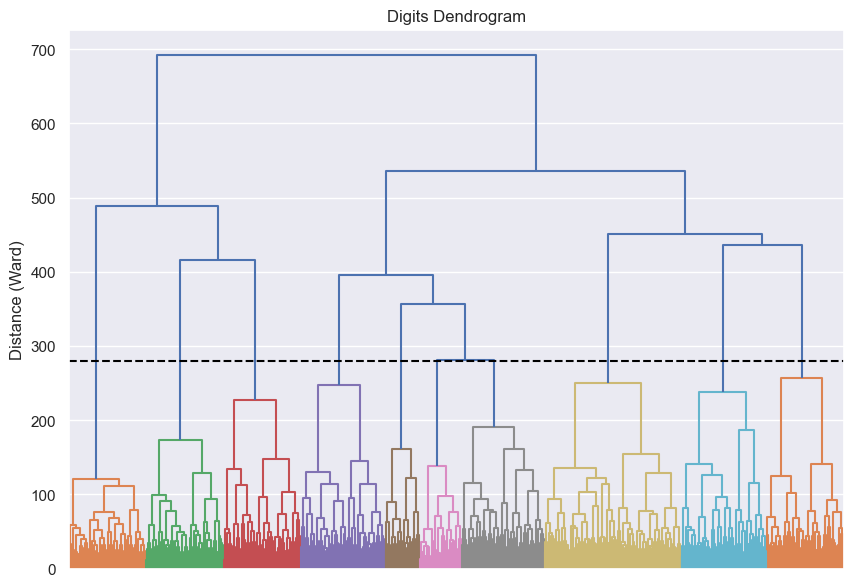

In [3]:
# linkage() performs all merges; every row of Z describes one merge
Z = shc.linkage(digits.data, method='ward')

plt.figure(figsize=(10, 7))
plt.title('Digits Dendrogram')
# color_threshold gives every branch below this height its own color
# no_labels hides the 1,797 leaf labels at the bottom, which would be unreadable
dend = shc.dendrogram(Z, color_threshold=280, no_labels=True)
plt.axhline(y=280, color='black', linestyle='--')
plt.ylabel('Distance (Ward)')
plt.show()

**Interpreting the dendrogram:**

- The dashed line at a height of 280 crosses **10** vertical lines, so it splits the images into 10 clusters, shown in different colors below the line.
- Since we know there are 10 different digits, we fit our model with 10 clusters.
- This is not necessarily the most *natural* cut. We'll investigate this in Question 1.

One of the key advantages of hierarchical clustering is its flexibility: if certain digits are too similar and end up in the same cluster, we can simply cut the tree at a different height. No need to fit the model again.

In [4]:
cluster = AgglomerativeClustering(n_clusters=10, linkage='ward')
# fit_predict() builds the hierarchy, cuts it at 10 clusters and returns the cluster number of every image
clusters = cluster.fit_predict(digits.data)
print('Number of images in each cluster:', np.bincount(clusters))

Number of images in each cluster: [181 317 197 196 191 178 181 178  80  98]


## 8.4 Exercises

##### Question 1: Try to fit the elbow plot for the hierarchical clustering model on the digits dataset.

For k-Means, we used the inertia (distortion) to create the elbow plot. Hierarchical clustering doesn't use centroids, so we use the **merge height** `Z[:, 2]` instead: the distance between the two clusters at the moment they merge.

The last row of `Z` is the final merge (2 clusters → 1), the row before it merges 3 clusters → 2, and so on. So if we take the last 32 merge heights and reverse them, the value at position k is the height of the merge that turns k + 1 clusters into k.

A **large drop** between k - 1 and k means that the k clusters are far apart from each other: a natural place to cut.

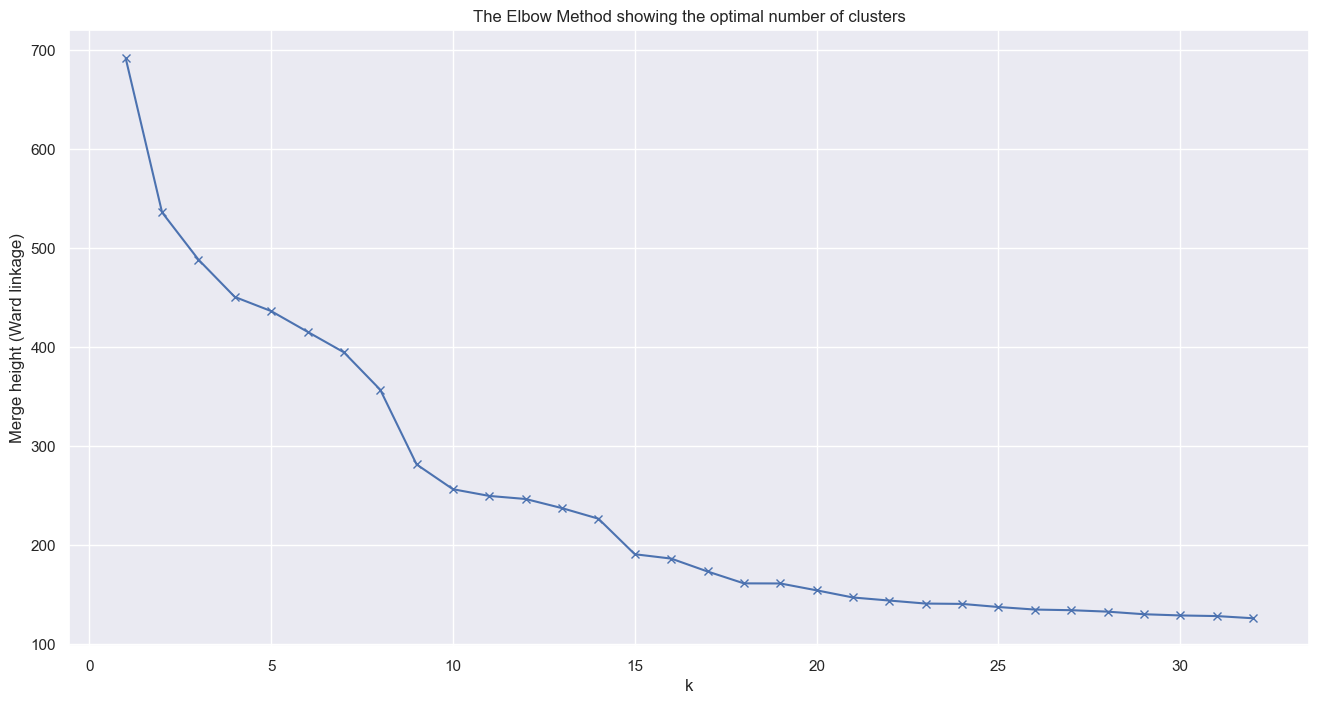

In [5]:
# Elbow method: take the last 32 merge heights and reverse them to match the increasing number of clusters
last = Z[-32:, 2]
last_rev = last[::-1]

plt.figure(figsize=(16, 8))
plt.plot(range(1, 33), last_rev, 'bx-')
plt.xlabel('k')
plt.ylabel('Merge height (Ward linkage)')
plt.title('The Elbow Method showing the optimal number of clusters')
plt.show()

The elbow is hard to read by eye, so let's calculate it. To get k clusters, we must cut between the merge that creates k clusters and the merge that creates k - 1 clusters. The bigger this **gap**, the more natural the cut:

In [6]:
# All merge heights from high to low: heights[0] is the final merge (2 clusters -> 1)
heights = Z[::-1, 2]

# To get k clusters, we cut somewhere between heights[k-1] (lower) and heights[k-2] (upper)
gaps = pd.DataFrame({'k': range(2, 16),
                     'cut from': heights[1:15],
                     'cut to': heights[0:14]})
gaps['gap'] = gaps['cut to'] - gaps['cut from']
gaps.sort_values('gap', ascending=False).head(7).round(1)

,k,cut from,cut to,gap
0,2,536.3,692.0,155.6
7,9,281.7,357.2,75.5
1,3,488.6,536.3,47.7
6,8,357.2,395.0,37.8
2,4,450.9,488.6,37.7
13,15,191.0,226.9,35.9
8,10,256.7,281.7,25.0


**Analyzing the elbow plot:**

| k | Gap | Interpretation |
|---|---|---|
| 2 | 155.6 | The largest gap, but 2 clusters is far too few for 10 digits |
| **9** | **75.5** | The clearest elbow after k = 2 |
| 10 | 25.0 | A reasonable choice, but a much weaker elbow than 9 |

- The curve drops much more irregularly than the k-Means elbow plots: each point is one single merge, and the size of the drop varies a lot from one merge to the next.
- The data itself points to **9 clusters** rather than 10. In the dendrogram, a cut gives 9 clusters anywhere between a height of 282 and 357, but 10 clusters only between 257 and 282.
- What does that 10th split do? With 9 clusters, one cluster contains both 167 eights and 96 ones. Going to 10 clusters splits it into an almost pure cluster of 8s and a pure cluster of 1s. So for recognizing digits, **10 clusters is the better choice**, even though 9 is the more natural cut.
- In both cases, the 3s and the 9s stay together in one cluster (169 threes and 145 nines): in pixel space, these digits are simply too close.

💡 **Practical insight:** the elbow tells us what the *data* suggests, but our *goal* (recognizing 10 digits) also matters when choosing the number of clusters. With hierarchical clustering, switching between 9 and 10 clusters only means cutting the tree at a different height.

##### Question 2: Try to split the dataset between test and train and check how accurate the best possible hierarchical clustering model is.

⚠️ Unlike `KMeans`, `AgglomerativeClustering` has **no `predict()` method**: it can only cluster the images it was fitted on. To evaluate the model on test images it has never seen, we do what k-Means does in its `predict()`, and assign each new image to the nearest cluster center:

| Step | Action | Uses labels? |
|---|---|---|
| 1 | Fit hierarchical clustering on the training images | No |
| 2 | Translate each cluster into its most common digit | Training labels only |
| 3 | Calculate the center (mean image) of each training cluster | No |
| 4 | Assign each test image to the nearest center and look up the digit of that cluster | No |
| 5 | Compare the predictions with the true test labels | Test labels, only to evaluate |

To find the *best possible* model, we repeat this for all four linkage methods.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=0)

def evaluate_hierarchical(linkage):
    # 1. Fit hierarchical clustering on the training images only
    train_clusters = AgglomerativeClustering(n_clusters=10, linkage=linkage).fit_predict(X_train)
    # 2. Translate each cluster into its most common digit, using the training labels only
    cluster_to_digit = np.array([mode(y_train[train_clusters == i])[0] for i in range(10)])
    # 3. The center of each cluster is the mean of its training images
    centers = np.array([X_train[train_clusters == i].mean(axis=0) for i in range(10)])
    # 4. Assign each test image to its nearest center and look up the digit of that cluster
    test_clusters = pairwise_distances_argmin(X_test, centers)
    train_predictions = cluster_to_digit[train_clusters]
    test_predictions = cluster_to_digit[test_clusters]
    return train_clusters, train_predictions, test_predictions

results = []
for linkage in ['ward', 'complete', 'average', 'single']:
    train_clusters, train_predictions, test_predictions = evaluate_hierarchical(linkage)
    # 5. Compare the predictions with the true labels
    results.append({'linkage': linkage,
                    'train accuracy': accuracy_score(y_train, train_predictions),
                    'test accuracy': accuracy_score(y_test, test_predictions),
                    'largest cluster': np.bincount(train_clusters).max()})

pd.DataFrame(results).round(3)

,linkage,train accuracy,test accuracy,largest cluster
0,ward,0.812,0.776,280
1,complete,0.679,0.729,247
2,average,0.704,0.651,272
3,single,0.114,0.131,1337


**Comparing the linkage methods:**

| Linkage | Test accuracy | Verdict |
|---|---|---|
| **Ward** | **77.6%** | Best model: compact clusters suit the digits |
| Complete | 72.9% | Decent, but clearly worse |
| Average | 65.1% | Several clusters are labeled with the same digit |
| Single | 13.1% | Chaining: one cluster contains 1,337 of the 1,347 training images |

- Ward's training accuracy (81.2%) and test accuracy (77.6%) are close: the model generalizes well to unseen images.
- Complete linkage scores *higher* on the test set than on the training set. This is because the test images are assigned with a different rule (nearest center, like k-Means) than the training images (complete linkage).

Let's take a closer look at the errors of the best model:

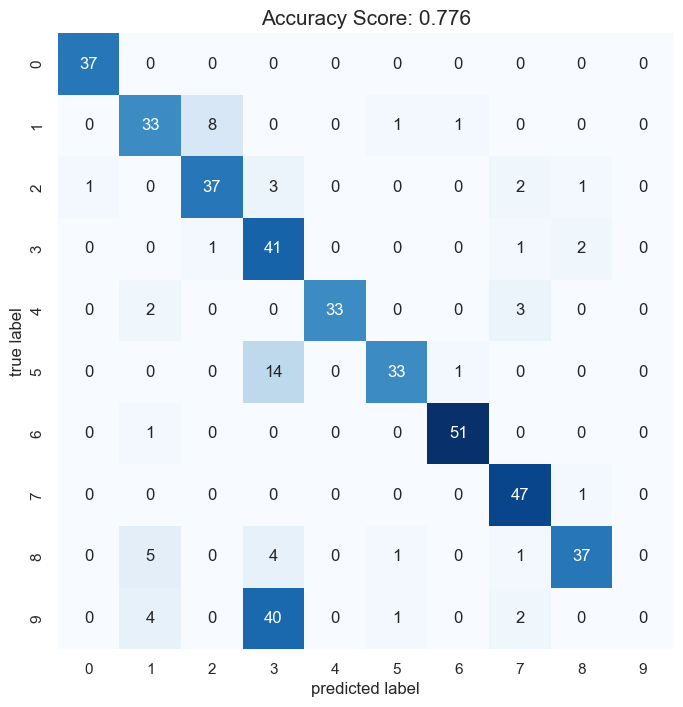

In [8]:
train_clusters, train_predictions, test_predictions = evaluate_hierarchical('ward')

cm = confusion_matrix(y_test, test_predictions)
plt.figure(figsize=(8, 8))
sns.heatmap(cm, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=digits.target_names, yticklabels=digits.target_names)
# confusion_matrix() puts the true labels in the rows and the predicted labels in the columns
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.title('Accuracy Score: %.3f' % accuracy_score(y_test, test_predictions), size=15)
plt.show()

**Model performance:**

We reach an accuracy of about **78%** on the test set. That's impressive, considering that:

- The model never saw the true labels while forming the clusters (only to name them afterwards)
- The test images played no role at all in building the model
- Random guessing would only give 10%

The most common mistakes:

| True digit | Predicted as | Count | Why? |
|---|---|---|---|
| 9 | 3 | 40 of 47 | No cluster is labeled as a 9: two clusters are labeled as a 1 instead |
| 5 | 3 | 14 of 48 | Both digits have a curve in the lower half |
| 1 | 2 | 8 of 43 | Some 1s are written with a base line at the bottom |

These are the same kind of errors that k-Means made in the previous chapter: some digits are so close in pixel space that they don't get a cluster of their own.

##### Question 3: Compare the hierarchical clustering and the $k$-means clustering algorithm for this dataset. Report which one provides the best fit. Is this what you would expect?

For a fair comparison, we evaluate both models in exactly the same way:

- **Full dataset:** cluster all 1,797 images and name each cluster after its most common digit (as in chapter 7 and section 8.3.2)
- **Train/test:** the approach from Question 2, on the same split as chapter 7

In [9]:
def cluster_accuracy(clusters, y):
    # Name each cluster after its most common digit and calculate the accuracy
    labels = np.zeros_like(clusters)
    for i in range(10):
        mask = (clusters == i)
        labels[mask] = mode(y[mask])[0]
    return accuracy_score(y, labels)

# Full dataset
hc_full = cluster_accuracy(AgglomerativeClustering(n_clusters=10, linkage='ward').fit_predict(digits.data), digits.target)
km_full = cluster_accuracy(KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(digits.data), digits.target)

# Train/test: hierarchical clustering with the function from Question 2
_, hc_train_predictions, hc_test_predictions = evaluate_hierarchical('ward')

# Train/test: k-Means can use its own predict() method
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
km_train_clusters = kmeans.fit_predict(X_train)
km_cluster_to_digit = np.array([mode(y_train[km_train_clusters == i])[0] for i in range(10)])
km_train_predictions = km_cluster_to_digit[km_train_clusters]
km_test_predictions = km_cluster_to_digit[kmeans.predict(X_test)]

comparison = pd.DataFrame({
    'full dataset': [hc_full, km_full],
    'train accuracy': [accuracy_score(y_train, hc_train_predictions), accuracy_score(y_train, km_train_predictions)],
    'test accuracy': [accuracy_score(y_test, hc_test_predictions), accuracy_score(y_test, km_test_predictions)]
}, index=['Hierarchical (Ward)', 'k-Means'])
comparison.round(3)

,full dataset,train accuracy,test accuracy
Hierarchical (Ward),0.862,0.812,0.776
k-Means,0.792,0.797,0.784


**Comparative analysis:**

| | Hierarchical (Ward) | k-Means | Winner |
|---|---|---|---|
| Full dataset | **86.2%** | 79.2% | Hierarchical (+7 percentage points) |
| Test set | 77.6% | **78.4%** | A tie (less than 1 point difference) |

**Which one provides the best fit?** As a *clustering* of the data, hierarchical clustering clearly wins: its 10 clusters match the true digits much better than the k-Means clusters. On the full dataset, its biggest mistake is merging the 9s with the 3s. k-Means makes more mistakes: no cluster is labeled as an 8, and many 5s and 8s end up in the cluster of the 9s.

**But on unseen images, the advantage disappears.** To predict a test image, we reduce every cluster to one center and assign the image to the nearest one. That is exactly how k-Means works, so in this step we actually turn our hierarchical model into a k-Means-like model.

**Is this what we would expect?** Partly:

| Expectation | Confirmed? |
|---|---|
| Ward linkage behaves similarly to k-Means (both minimize the variance within the clusters) | ✅ Yes: similar accuracy, similar types of errors |
| Building the clusters step by step gives a better grouping than k-Means' center updates | ✅ Yes, on the full dataset |
| Hierarchical clustering handles irregular cluster shapes better | ❌ Only with single linkage, and that failed completely here (13%) |
| k-Means suffers from random initialization | ❌ Barely: with `n_init=10`, the accuracy only changes between 79.1% and 79.7% for different random seeds |

**When is k-Means the better choice?**

- **Large datasets:** hierarchical clustering needs the distances between all pairs of observations, which becomes very slow and memory-hungry
- **New observations:** k-Means has a `predict()` method; for hierarchical clustering we need a workaround like in Question 2
- **Known number of clusters:** then the flexibility of the hierarchy isn't needed

## 8.5 Key Takeaways

| | |
|---|---|
| **Idea** | Start with every observation as its own cluster and repeatedly merge the two closest clusters |
| **Dendrogram** | Shows every merge; cut it at a chosen height to get the clusters |
| **Linkage** | Defines the distance between clusters; **Ward** is usually the best choice |
| **Number of clusters** | Look for the largest gap between merge heights, but also take your goal into account |
| **Deterministic** | No random initialization: the same data always gives the same tree |
| **Limitations** | Slow on large datasets, and no `predict()` for new observations |

**On the digits dataset:** hierarchical clustering (Ward) finds clusters that match the digits better than k-Means (86% versus 79%), but when it comes to predicting unseen images, both methods perform about the same (around 78%).